# Customer Churn Analysis and Retention

In [5]:
import pandas as pd
import numpy as np

# Data Collection and Inspection

In [7]:
df=pd.read_csv("Customer churn dataset.csv")

In [8]:
df.head

<bound method NDFrame.head of      Customer_ID     Customer_Name  Gender   Age          State        City  \
0          C1000  Abhishek Jaiswal  Female  35.0    Maharashtra        Pune   
1          C1001       Rohit Kumar    Male   NaN          Delhi       Noida   
2          C1002       Pooja Singh  Female  42.0             UP      Kanpur   
3          C1003               NaN    Male  59.0      Karnataka   Bengaluru   
4          C1004       Mohit Arora   male   26.0        Gujarat   Ahmedabad   
...          ...               ...     ...   ...            ...         ...   
9995      C10995       Ishaan Nair  Female  26.0      Telangana       Delhi   
9996      C10996      Sneha Sharma  Female  76.0            NaN      Mysuru   
9997      C10997       Diya Joseph  Female  52.0      Karnataka  Coimbatore   
9998      C10998        Nikhil Das    Male  76.0  Uttar Pradesh    Palakkad   
9999      C10999       Diya Pillai  Female  51.0      Rajasthan        Pune   

      Tenure_Months S

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            10000 non-null  object 
 1   Customer_Name          9892 non-null   object 
 2   Gender                 9929 non-null   object 
 3   Age                    9927 non-null   float64
 4   State                  9884 non-null   object 
 5   City                   9913 non-null   object 
 6   Tenure_Months          9902 non-null   float64
 7   Subscription_Type      9866 non-null   object 
 8   Monthly_Charges        9919 non-null   float64
 9   Total_Charges          9896 non-null   float64
 10  Contract_Type          9920 non-null   object 
 11  Payment_Method         9855 non-null   object 
 12  Internet_Service       9929 non-null   object 
 13  Tech_Support           9886 non-null   object 
 14  Senior_Citizen         9927 non-null   object 
 15  Dep

In [9]:
df.describe()

,Age,Tenure_Months,Monthly_Charges,Total_Charges
count,9927.000000,9902.000000,9919.000000,9896.000000
mean,48.441019,36.885074,165.298924,6159.342703
std,18.249229,20.719351,326.252300,14462.756000
min,3.000000,1.000000,-2454.770000,-99781.820000
25%,33.000000,19.000000,61.295000,1428.387500
50%,48.000000,37.000000,103.380000,3119.845000
75%,64.000000,55.000000,146.795000,5937.032500
max,165.000000,72.000000,2492.510000,171429.830000


In [15]:
df.isnull().sum()/len(df)*100

Customer_ID              0.00
Customer_Name            1.08
Gender                   0.71
Age                      0.73
State                    1.16
City                     0.87
Tenure_Months            0.98
Subscription_Type        1.34
Monthly_Charges          0.81
Total_Charges            1.04
Contract_Type            0.80
Payment_Method           1.45
Internet_Service         0.71
Tech_Support             1.14
Senior_Citizen           0.73
Dependents               0.69
Churn                    0.66
Last_Interaction_Date    0.48
dtype: float64

In [13]:
df.shape

(10000, 18)

# To find number of missing values

In [22]:
df.isnull().sum()/len(df)*100

Customer_ID              0.00
Customer_Name            1.08
Gender                   0.71
Age                      0.73
State                    1.16
City                     0.87
Tenure_Months            0.98
Subscription_Type        1.34
Monthly_Charges          0.81
Total_Charges            1.04
Contract_Type            0.80
Payment_Method           1.45
Internet_Service         0.71
Tech_Support             1.14
Senior_Citizen           0.73
Dependents               0.69
Churn                    0.66
Last_Interaction_Date    0.48
dtype: float64

In [20]:
df.shape

(10000, 18)

In [24]:
df.dropna()

,Customer_ID,Customer_Name,Gender,Age,State,City,Tenure_Months,Subscription_Type,Monthly_Charges,Total_Charges,Contract_Type,Payment_Method,Internet_Service,Tech_Support,Senior_Citizen,Dependents,Churn,Last_Interaction_Date
0,C1000,Abhishek Jaiswal,Female,35.0,Maharashtra,Pune,58.0,basic,1614.26,93273.08,One Year,UPI,Fiber,Yes,No,Yes,No,12-10-2025
2,C1002,Pooja Singh,Female,42.0,UP,Kanpur,13.0,Basic,555.03,6869.39,Month-to-Month,Debit Card,5G,No,No,No,Yes,20-02-2026
4,C1004,Mohit Arora,male,26.0,Gujarat,Ahmedabad,6.0,Premium,314.02,1926.12,One Year,Debit Card,Cable,Yes,No,No,No,02-04-2026
6,C1006,Neha Verma,Female,18.0,Delhi,Noida,70.0,Standard,2008.83,140376.10,Month-to-Month,UPI,DSL,Yes,No,No,No,26-12-2025
7,C1007,Vikas Yadav,Male,61.0,Delhi,,57.0,Basic,2196.18,125145.26,One Year,Cash,Cable,Yes,Yes,Yes,No,14-01-2025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9993,C10993,Sneha Patel,Female,77.0,Delhi,Coimbatore,51.0,Basic,103.22,5713.28,One Year,Debit Card,Cable,No,Yes,No,No,10-02-2026
9994,C10994,Kavya Menon,Female,67.0,Delhi,Bengaluru,5.0,Family,44.21,241.56,Two Year,UPI,No,No,Yes,No,Yes,15-10-2024
9997,C10997,Diya Joseph,Female,52.0,Karnataka,Coimbatore,61.0,Basic,179.18,9788.59,Two Year,Debit Card,No,Yes,No,No,Yes,31-05-2026
9998,C10998,Nikhil Das,Male,76.0,Uttar Pradesh,Palakkad,49.0,Premium,58.78,3208.95,Monthly,E-Wallet,No,Yes,Yes,Yes,Yes,26-02-2026


In [26]:
df.dropna().shape

(8599, 18)

In [28]:
df[df.duplicated()].shape

(7, 18)

In [30]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
9995    False
9996    False
9997    False
9998    False
9999    False
Length: 10000, dtype: bool

In [34]:
df['Customer_ID'].value_counts().head(10)

Customer_ID
C1018    3
C2001    2
C5001    2
C5008    2
C5007    2
C5006    2
C5005    2
C5004    2
C5003    2
C5002    2
Name: count, dtype: int64

In [36]:
df[df['Customer_ID'] == 'C2001']

,Customer_ID,Customer_Name,Gender,Age,State,City,Tenure_Months,Subscription_Type,Monthly_Charges,Total_Charges,Contract_Type,Payment_Method,Internet_Service,Tech_Support,Senior_Citizen,Dependents,Churn,Last_Interaction_Date
532,C2001,Abhishek Jaiswal,Female,35.0,Maharashtra,Pune,58.0,basic,1614.26,93273.08,One Year,UPI,Fiber,Yes,No,Yes,No,12-10-2025
1001,C2001,Vivek Kumar,Male,52.0,Delhi,Kolkata,40.0,Premium,50.01,1773.94,Monthly,Bank Transfer,Cable,Yes,No,Yes,Yes,28-03-2026


In [40]:
for col in df.columns:
    if df[col].nunique() < 20:
        print(df[col].value_counts())
        print('-'*50)

Gender
Male      5018
Female    4672
male       128
female     109
 male        2
Name: count, dtype: int64
--------------------------------------------------
State
Delhi            1072
Gujarat          1037
Maharashtra      1022
Karnataka         990
Kerala            980
Tamil Nadu        962
Uttar Pradesh     948
Rajasthan         942
West Bengal       915
Telangana         897
UP                113
Gujarat             3
Delhi               2
  UP                1
Name: count, dtype: int64
--------------------------------------------------
City
Delhi                 844
Kochi                 827
Chennai               817
Pune                  813
Bengaluru             810
Mysuru                807
Mumbai                806
Coimbatore            804
Kolkata               787
Thiruvananthapuram    771
Palakkad              769
Hyderabad             769
Ahmedabad              64
Lucknow                61
Surat                  56
Noida                  54
Kanpur                 51
   

# Handling Missing Values

In [43]:
df.dropna(subset=['Customer_ID'], inplace = True)

In [45]:
df.isnull().sum()

Customer_ID                0
Customer_Name            108
Gender                    71
Age                       73
State                    116
City                      87
Tenure_Months             98
Subscription_Type        134
Monthly_Charges           81
Total_Charges            104
Contract_Type             80
Payment_Method           145
Internet_Service          71
Tech_Support             114
Senior_Citizen            73
Dependents                69
Churn                     66
Last_Interaction_Date     48
dtype: int64

In [49]:
df

,Customer_ID,Customer_Name,Gender,Age,State,City,Tenure_Months,Subscription_Type,Monthly_Charges,Total_Charges,Contract_Type,Payment_Method,Internet_Service,Tech_Support,Senior_Citizen,Dependents,Churn,Last_Interaction_Date
0,C1000,Abhishek Jaiswal,Female,35.0,Maharashtra,Pune,58.0,basic,1614.26,93273.08,One Year,UPI,Fiber,Yes,No,Yes,No,12-10-2025
1,C1001,Rohit Kumar,Male,NaN,Delhi,Noida,36.0,Premium,429.60,15858.60,Two Year,Cash,DSL,Yes,Yes,No,No,05-03-2026
2,C1002,Pooja Singh,Female,42.0,UP,Kanpur,13.0,Basic,555.03,6869.39,Month-to-Month,Debit Card,5G,No,No,No,Yes,20-02-2026
3,C1003,NaN,Male,59.0,Karnataka,Bengaluru,55.0,Standard,NaN,101349.10,Two Year,UPI,5G,No,No,Yes,No,07-06-2026
4,C1004,Mohit Arora,male,26.0,Gujarat,Ahmedabad,6.0,Premium,314.02,1926.12,One Year,Debit Card,Cable,Yes,No,No,No,02-04-2026
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,C10995,Ishaan Nair,Female,26.0,Telangana,Delhi,40.0,Basic,NaN,4436.27,Two Year,UPI,DSL,No,No,Yes,Yes,05-10-2024
9996,C10996,Sneha Sharma,Female,76.0,NaN,Mysuru,7.0,Basic,97.60,650.05,One Year,Bank Transfer,Fiber Optic,No,Yes,No,No,21-05-2025
9997,C10997,Diya Joseph,Female,52.0,Karnataka,Coimbatore,61.0,Basic,179.18,9788.59,Two Year,Debit Card,No,Yes,No,No,Yes,31-05-2026
9998,C10998,Nikhil Das,Male,76.0,Uttar Pradesh,Palakkad,49.0,Premium,58.78,3208.95,Monthly,E-Wallet,No,Yes,Yes,Yes,Yes,26-02-2026


In [51]:
df['Age'].unique()

array([ 35.,  nan,  42.,  59.,  26., 115.,  18.,  61.,  45.,  25.,  60.,
         3.,  41.,  50., 120.,  24.,  22.,  33.,   4.,  48.,  69.,  70.,
         5.,  40.,  37.,  19.,  29.,  38.,  21.,  68.,  28.,  36.,  23.,
        44.,  58., 140.,  47.,  67.,  53.,  66.,  27.,  32.,  56.,  34.,
       137.,  63.,  54.,  65.,  49.,  62.,  20.,  43.,  31.,  57.,  30.,
       121.,  39.,  51.,  64.,  52.,  46.,  55., 165.,  72.,  78.,  75.,
        71.,  73.,  74.,  79.,  80.,  76.,  77.])

In [82]:
df_age = df[df['Age']!= 'nan years']['Age']

In [84]:
df_age

0       35.0
1        NaN
2       42.0
3       59.0
4       26.0
        ... 
9995    26.0
9996    76.0
9997    52.0
9998    76.0
9999    51.0
Name: Age, Length: 10000, dtype: float64

In [86]:
cleaned_age = df['Age'].dropna()

In [88]:
df

,Customer_ID,Customer_Name,Gender,Age,State,City,Tenure_Months,Subscription_Type,Monthly_Charges,Total_Charges,Contract_Type,Payment_Method,Internet_Service,Tech_Support,Senior_Citizen,Dependents,Churn,Last_Interaction_Date
0,C1000,Abhishek Jaiswal,Female,35.0,Maharashtra,Pune,58.0,basic,1614.26,93273.08,One Year,UPI,Fiber,Yes,No,Yes,No,12-10-2025
1,C1001,Rohit Kumar,Male,NaN,Delhi,Noida,36.0,Premium,429.60,15858.60,Two Year,Cash,DSL,Yes,Yes,No,No,05-03-2026
2,C1002,Pooja Singh,Female,42.0,UP,Kanpur,13.0,Basic,555.03,6869.39,Month-to-Month,Debit Card,5G,No,No,No,Yes,20-02-2026
3,C1003,NaN,Male,59.0,Karnataka,Bengaluru,55.0,Standard,NaN,101349.10,Two Year,UPI,5G,No,No,Yes,No,07-06-2026
4,C1004,Mohit Arora,male,26.0,Gujarat,Ahmedabad,6.0,Premium,314.02,1926.12,One Year,Debit Card,Cable,Yes,No,No,No,02-04-2026
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,C10995,Ishaan Nair,Female,26.0,Telangana,Delhi,40.0,Basic,NaN,4436.27,Two Year,UPI,DSL,No,No,Yes,Yes,05-10-2024
9996,C10996,Sneha Sharma,Female,76.0,NaN,Mysuru,7.0,Basic,97.60,650.05,One Year,Bank Transfer,Fiber Optic,No,Yes,No,No,21-05-2025
9997,C10997,Diya Joseph,Female,52.0,Karnataka,Coimbatore,61.0,Basic,179.18,9788.59,Two Year,Debit Card,No,Yes,No,No,Yes,31-05-2026
9998,C10998,Nikhil Das,Male,76.0,Uttar Pradesh,Palakkad,49.0,Premium,58.78,3208.95,Monthly,E-Wallet,No,Yes,Yes,Yes,Yes,26-02-2026


In [90]:
cleaned_age = df['Age'].dropna().reset_index(drop=True)

In [94]:
# Option A: Drop rows in place (modifies the existing df)
df.dropna(subset=['Age'], inplace=True)

# Option B: Create a new DataFrame without those rows
df_cleaned = df.dropna(subset=['Age'])

In [96]:
# Fill NaN with the median age
median_age = df['Age'].median()
df['Age'] = df['Age'].fillna(median_age)

# Or fill with a placeholder like 0 or a string
df['Age'] = df['Age'].fillna(0)

In [98]:
df

,Customer_ID,Customer_Name,Gender,Age,State,City,Tenure_Months,Subscription_Type,Monthly_Charges,Total_Charges,Contract_Type,Payment_Method,Internet_Service,Tech_Support,Senior_Citizen,Dependents,Churn,Last_Interaction_Date
0,C1000,Abhishek Jaiswal,Female,35.0,Maharashtra,Pune,58.0,basic,1614.26,93273.08,One Year,UPI,Fiber,Yes,No,Yes,No,12-10-2025
2,C1002,Pooja Singh,Female,42.0,UP,Kanpur,13.0,Basic,555.03,6869.39,Month-to-Month,Debit Card,5G,No,No,No,Yes,20-02-2026
3,C1003,NaN,Male,59.0,Karnataka,Bengaluru,55.0,Standard,NaN,101349.10,Two Year,UPI,5G,No,No,Yes,No,07-06-2026
4,C1004,Mohit Arora,male,26.0,Gujarat,Ahmedabad,6.0,Premium,314.02,1926.12,One Year,Debit Card,Cable,Yes,No,No,No,02-04-2026
5,C1005,Sneha Jain,Female,115.0,Gujarat,Surat,1.0,NaN,1633.64,1707.64,Two Year,Debit Card,Cable,No,No,Yes,No,13-03-2026
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,C10995,Ishaan Nair,Female,26.0,Telangana,Delhi,40.0,Basic,NaN,4436.27,Two Year,UPI,DSL,No,No,Yes,Yes,05-10-2024
9996,C10996,Sneha Sharma,Female,76.0,NaN,Mysuru,7.0,Basic,97.60,650.05,One Year,Bank Transfer,Fiber Optic,No,Yes,No,No,21-05-2025
9997,C10997,Diya Joseph,Female,52.0,Karnataka,Coimbatore,61.0,Basic,179.18,9788.59,Two Year,Debit Card,No,Yes,No,No,Yes,31-05-2026
9998,C10998,Nikhil Das,Male,76.0,Uttar Pradesh,Palakkad,49.0,Premium,58.78,3208.95,Monthly,E-Wallet,No,Yes,Yes,Yes,Yes,26-02-2026


In [100]:
# Drops any row containing a NaN value
df_cleaned = df.dropna()

In [102]:
# Drop rows where NaN is present only in 'Customer_Name' or 'Age'
df_cleaned = df.dropna(subset=['Customer_Name', 'Age'])

In [104]:
df['Customer_Name'] = df['Customer_Name'].fillna('Unknown')
df['State'] = df['State'].fillna('Unknown')

In [106]:
# Fill missing Age with the median age
df['Age'] = df['Age'].fillna(df['Age'].median())

# Fill missing Monthly Charges with 0 or the mean
df['Monthly_Charges'] = df['Monthly_Charges'].fillna(0)

In [108]:
print(df.isnull().sum())

Customer_ID                0
Customer_Name              0
Gender                    71
Age                        0
State                      0
City                      87
Tenure_Months             97
Subscription_Type        133
Monthly_Charges            0
Total_Charges            103
Contract_Type             79
Payment_Method           145
Internet_Service          70
Tech_Support             111
Senior_Citizen            71
Dependents                69
Churn                     65
Last_Interaction_Date     48
dtype: int64


In [128]:
categorical_cols = [
    'Gender', 'City', 'Subscription_Type', 'Contract_Type', 
    'Payment_Method', 'Internet_Service', 'Tech_Support', 
    'Senior_Citizen', 'Dependents', 'Churn'
]

# Fill missing categorical values with 'Unknown'
for col in categorical_cols:
    if col in df.columns:
        df[col] = df[col].fillna('Unknown')

In [130]:
# Fill missing numerical values with the median
df['Tenure_Months'] = df['Tenure_Months'].fillna(df['Tenure_Months'].median())
df['Total_Charges'] = df['Total_Charges'].fillna(df['Total_Charges'].median())

In [132]:
# 1. Fill Numerical columns with median
num_cols = ['Tenure_Months', 'Total_Charges']
for col in num_cols:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())

# 2. Fill Categorical columns with 'Unknown'
cat_cols = [
    'Gender', 'City', 'Subscription_Type', 'Contract_Type', 
    'Payment_Method', 'Internet_Service', 'Tech_Support', 
    'Senior_Citizen', 'Dependents', 'Churn', 'Last_Interaction_Date'
]
for col in cat_cols:
    if col in df.columns:
        df[col] = df[col].fillna('Unknown')

# Verify no NaNs are left
print(df.isnull().sum())

Customer_ID              0
Customer_Name            0
Gender                   0
Age                      0
State                    0
City                     0
Tenure_Months            0
Subscription_Type        0
Monthly_Charges          0
Total_Charges            0
Contract_Type            0
Payment_Method           0
Internet_Service         0
Tech_Support             0
Senior_Citizen           0
Dependents               0
Churn                    0
Last_Interaction_Date    0
dtype: int64


In [134]:
df

,Customer_ID,Customer_Name,Gender,Age,State,City,Tenure_Months,Subscription_Type,Monthly_Charges,Total_Charges,Contract_Type,Payment_Method,Internet_Service,Tech_Support,Senior_Citizen,Dependents,Churn,Last_Interaction_Date
0,C1000,Abhishek Jaiswal,Female,35.0,Maharashtra,Pune,58.0,basic,1614.26,93273.08,One Year,UPI,Fiber,Yes,No,Yes,No,12-10-2025
2,C1002,Pooja Singh,Female,42.0,UP,Kanpur,13.0,Basic,555.03,6869.39,Month-to-Month,Debit Card,5G,No,No,No,Yes,20-02-2026
3,C1003,Unknown,Male,59.0,Karnataka,Bengaluru,55.0,Standard,0.00,101349.10,Two Year,UPI,5G,No,No,Yes,No,07-06-2026
4,C1004,Mohit Arora,male,26.0,Gujarat,Ahmedabad,6.0,Premium,314.02,1926.12,One Year,Debit Card,Cable,Yes,No,No,No,02-04-2026
6,C1006,Neha Verma,Female,18.0,Delhi,Noida,70.0,Standard,2008.83,140376.10,Month-to-Month,UPI,DSL,Yes,No,No,No,26-12-2025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,C10995,Ishaan Nair,Female,26.0,Telangana,Delhi,40.0,Basic,0.00,4436.27,Two Year,UPI,DSL,No,No,Yes,Yes,05-10-2024
9996,C10996,Sneha Sharma,Female,76.0,Unknown,Mysuru,7.0,Basic,97.60,650.05,One Year,Bank Transfer,Fiber Optic,No,Yes,No,No,21-05-2025
9997,C10997,Diya Joseph,Female,52.0,Karnataka,Coimbatore,61.0,Basic,179.18,9788.59,Two Year,Debit Card,No,Yes,No,No,Yes,31-05-2026
9998,C10998,Nikhil Das,Male,76.0,Uttar Pradesh,Palakkad,49.0,Premium,58.78,3208.95,Monthly,E-Wallet,No,Yes,Yes,Yes,Yes,26-02-2026


# Fix Inconsistent Formatting

In [137]:
df['Gender'].unique()

array(['Female', 'Male', ' male ', 'female', 'male'], dtype=object)

In [139]:
df['Gender'].str.lower()

0       female
2       female
3         male
4        male 
6       female
         ...  
9995    female
9996    female
9997    female
9998      male
9999    female
Name: Gender, Length: 8856, dtype: object

In [141]:
df['Gender'].str.lower().unique()

array(['female', 'male', ' male '], dtype=object)

In [166]:
df['Gender'].replace({'m':'male','f':'female'},inplace = True)

In [149]:
df['Gender']

0       Female
2       Female
3         Male
4        male 
6       Female
         ...  
9995    Female
9996    Female
9997    Female
9998      Male
9999    Female
Name: Gender, Length: 8856, dtype: object

In [151]:
df['Gender'].unique()

array(['Female', 'Male', ' male ', 'female', 'male'], dtype=object)

In [153]:
df['City'].str.strip().str.strip().str.lower()

0             pune
2           kanpur
3        bengaluru
4        ahmedabad
6            noida
           ...    
9995         delhi
9996        mysuru
9997    coimbatore
9998      palakkad
9999          pune
Name: City, Length: 8856, dtype: object

In [ ]:
df['Country'].str.lower()

In [163]:
df

,Customer_ID,Customer_Name,Gender,Age,State,City,Tenure_Months,Subscription_Type,Monthly_Charges,Total_Charges,Contract_Type,Payment_Method,Internet_Service,Tech_Support,Senior_Citizen,Dependents,Churn,Last_Interaction_Date
0,C1000,Abhishek Jaiswal,Female,35.0,Maharashtra,Pune,58.0,basic,1614.26,93273.08,One Year,UPI,Fiber,Yes,No,Yes,No,12-10-2025
2,C1002,Pooja Singh,Female,42.0,UP,Kanpur,13.0,Basic,555.03,6869.39,Month-to-Month,Debit Card,5G,No,No,No,Yes,20-02-2026
3,C1003,Unknown,Male,59.0,Karnataka,Bengaluru,55.0,Standard,0.00,101349.10,Two Year,UPI,5G,No,No,Yes,No,07-06-2026
4,C1004,Mohit Arora,male,26.0,Gujarat,Ahmedabad,6.0,Premium,314.02,1926.12,One Year,Debit Card,Cable,Yes,No,No,No,02-04-2026
6,C1006,Neha Verma,Female,18.0,Delhi,Noida,70.0,Standard,2008.83,140376.10,Month-to-Month,UPI,DSL,Yes,No,No,No,26-12-2025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,C10995,Ishaan Nair,Female,26.0,Telangana,Delhi,40.0,Basic,0.00,4436.27,Two Year,UPI,DSL,No,No,Yes,Yes,05-10-2024
9996,C10996,Sneha Sharma,Female,76.0,Unknown,Mysuru,7.0,Basic,97.60,650.05,One Year,Bank Transfer,Fiber Optic,No,Yes,No,No,21-05-2025
9997,C10997,Diya Joseph,Female,52.0,Karnataka,Coimbatore,61.0,Basic,179.18,9788.59,Two Year,Debit Card,No,Yes,No,No,Yes,31-05-2026
9998,C10998,Nikhil Das,Male,76.0,Uttar Pradesh,Palakkad,49.0,Premium,58.78,3208.95,Monthly,E-Wallet,No,Yes,Yes,Yes,Yes,26-02-2026


# Handling Duplicates

In [188]:
df_cleaned = df_cleaned.drop_duplicates(keep='first')
df_cleaned.shape

(9815, 18)

In [190]:
df_cleaned['Customer_ID'].value_counts()

Customer_ID
C2001     2
C5009     2
C5008     2
C5007     2
C5006     2
         ..
C4347     1
C4348     1
C4349     1
C4350     1
C10999    1
Name: count, Length: 9806, dtype: int64

# Check duplicates based on customer_id

In [195]:
partial_duplicates = df_cleaned[df_cleaned.duplicated(subset=['Customer_ID'], keep=False)]
print(f"🔍 Partial Duplicates (Customer ID): {partial_duplicates.shape[0]}")

partial_duplicates.sort_values(by='Customer_ID').head(10)

🔍 Partial Duplicates (Customer ID): 18


,Customer_ID,Customer_Name,Gender,Age,State,City,Tenure_Months,Subscription_Type,Monthly_Charges,Total_Charges,Contract_Type,Payment_Method,Internet_Service,Tech_Support,Senior_Citizen,Dependents,Churn,Last_Interaction_Date
18,C1018,Amit Sharma,NaN,41.0,Gujarat,Ahmedabad,48.0,Premium,2328.32,111299.36,Month-to-Month,Net Banking,Fiber,Yes,No,Yes,No,04-06-2025
524,C1018,Anikta Sharma,Female,41.0,Gujarat,Ahmedabad,48.0,Premium,2328.32,111299.36,Month-to-Month,Net Banking,Fiber,Yes,No,Yes,No,04-06-2025
532,C2001,Abhishek Jaiswal,Female,35.0,Maharashtra,Pune,58.0,basic,1614.26,93273.08,One Year,UPI,Fiber,Yes,No,Yes,No,12-10-2025
1001,C2001,Vivek Kumar,Male,52.0,Delhi,Kolkata,40.0,Premium,50.01,1773.94,Monthly,Bank Transfer,Cable,Yes,No,Yes,Yes,28-03-2026
534,C5002,Pooja Singh,Female,42.0,UP,Kanpur,13.0,Basic,555.03,6869.39,Month-to-Month,Debit Card,5G,No,No,No,Yes,20-02-2026
4002,C5002,Ishaan Gupta,Male,35.0,Gujarat,Coimbatore,22.0,Basic,178.13,3621.40,Monthly,Credit Card,No,Yes,No,No,No,24-07-2026
536,C5004,Mohit Arora,male,26.0,Gujarat,Ahmedabad,6.0,Premium,314.02,1926.12,One Year,Debit Card,Cable,Yes,No,No,No,02-04-2026
4004,C5004,Rahul Das,Male,80.0,Kerala,Mumbai,59.0,Basic,103.09,5659.84,One Year,Cash,Cable,Yes,Yes,No,No,09-01-2025
537,C5005,Sneha Jain,Female,115.0,Gujarat,Surat,1.0,NaN,1633.64,1707.64,Two Year,Debit Card,Cable,No,No,Yes,No,13-03-2026
4005,C5005,Neha Patel,Male,27.0,Delhi,Mumbai,52.0,Basic,24.93,1449.53,Monthly,UPI,Cable,Yes,No,No,No,25-12-2024


In [197]:
df_cleaned = df_cleaned.drop_duplicates(subset=['Customer_ID'], keep='first')
df_cleaned.shape

(9806, 18)

# Correct data types

In [206]:
# Convert to datetime, turning any invalid/unparseable dates into NaT
df_cleaned['Last_Interaction_Date'] = pd.to_datetime(df_cleaned['Last_Interaction_Date'], errors='coerce')

# Convert Age to integer
df_cleaned['Age'] = df_cleaned['Age'].astype('int64')

# Check data types
print(df_cleaned.dtypes)

Customer_ID                      object
Customer_Name                    object
Gender                           object
Age                               int64
State                            object
City                             object
Tenure_Months                   float64
Subscription_Type                object
Monthly_Charges                 float64
Total_Charges                   float64
Contract_Type                    object
Payment_Method                   object
Internet_Service                 object
Tech_Support                     object
Senior_Citizen                   object
Dependents                       object
Churn                            object
Last_Interaction_Date    datetime64[ns]
dtype: object


# Handling Outliers

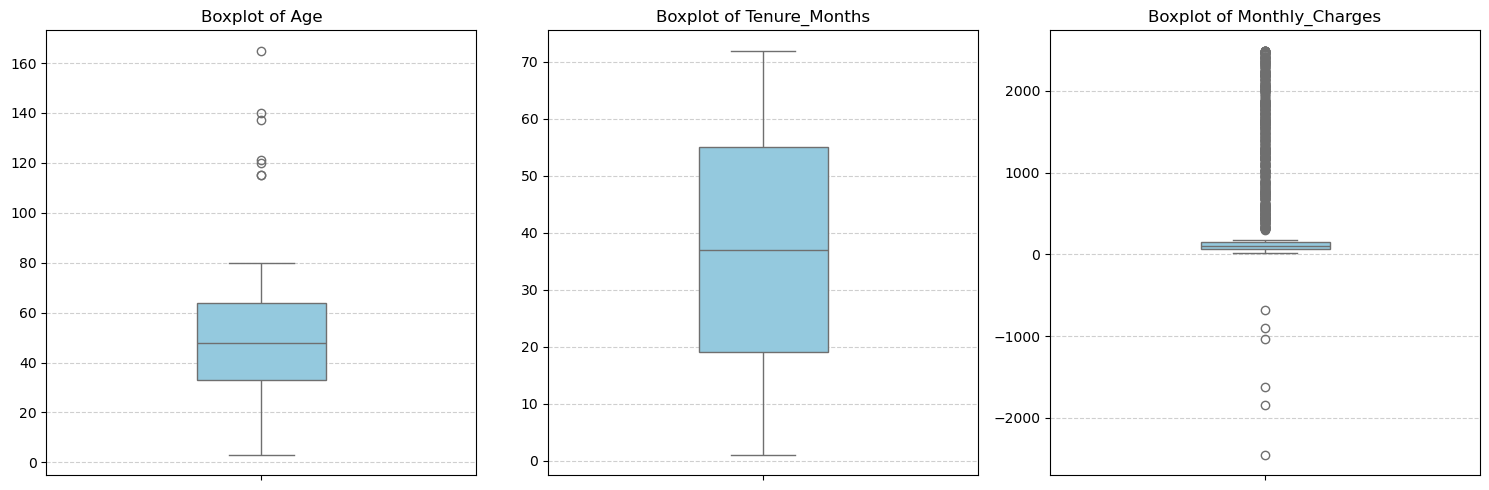

In [215]:
import matplotlib.pyplot as plt
import seaborn as sns

# Use columns that actually exist in your DataFrame
cols = ['Age', 'Tenure_Months', 'Monthly_Charges']

plt.figure(figsize=(15, 5))

for i, col in enumerate(cols, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df_cleaned[col], color='skyblue', width=0.3)
    plt.title(f'Boxplot of {col}', fontsize=12)
    plt.ylabel('')
    plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [237]:
outlier_cols = ['Age', 'Tenure_Months', 'Monthly_Charges']

In [241]:
z_scores = np.abs(stats.zscore(df_cleaned[outlier_cols]))

In [243]:
outlier_mask = (z_scores > 3).any(axis=1)

In [245]:
df_final = df_cleaned[~outlier_mask].copy()

In [249]:
df_final.to_csv('cleaned_customer_data.csv', index=False)

In [251]:
import os
print("Current working folder:", os.getcwd())

Current working folder: C:\Users\aishu


In [253]:
df_final

,Customer_ID,Customer_Name,Gender,Age,State,City,Tenure_Months,Subscription_Type,Monthly_Charges,Total_Charges,Contract_Type,Payment_Method,Internet_Service,Tech_Support,Senior_Citizen,Dependents,Churn,Last_Interaction_Date
0,C1000,Abhishek Jaiswal,Female,35,Maharashtra,Pune,58.0,basic,1614.26,93273.08,One Year,UPI,Fiber,Yes,No,Yes,No,2025-12-10
2,C1002,Pooja Singh,Female,42,UP,Kanpur,13.0,Basic,555.03,6869.39,Month-to-Month,Debit Card,5G,No,No,No,Yes,NaT
4,C1004,Mohit Arora,male,26,Gujarat,Ahmedabad,6.0,Premium,314.02,1926.12,One Year,Debit Card,Cable,Yes,No,No,No,2026-02-04
6,C1006,Neha Verma,Female,18,Delhi,Noida,70.0,Standard,2008.83,140376.10,Month-to-Month,UPI,DSL,Yes,No,No,No,NaT
7,C1007,Vikas Yadav,Male,61,Delhi,,57.0,Basic,2196.18,125145.26,One Year,Cash,Cable,Yes,Yes,Yes,No,NaT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,C10995,Ishaan Nair,Female,26,Telangana,Delhi,40.0,Basic,NaN,4436.27,Two Year,UPI,DSL,No,No,Yes,Yes,2024-05-10
9996,C10996,Sneha Sharma,Female,76,NaN,Mysuru,7.0,Basic,97.60,650.05,One Year,Bank Transfer,Fiber Optic,No,Yes,No,No,NaT
9997,C10997,Diya Joseph,Female,52,Karnataka,Coimbatore,61.0,Basic,179.18,9788.59,Two Year,Debit Card,No,Yes,No,No,Yes,NaT
9998,C10998,Nikhil Das,Male,76,Uttar Pradesh,Palakkad,49.0,Premium,58.78,3208.95,Monthly,E-Wallet,No,Yes,Yes,Yes,Yes,NaT


In [255]:
# Tell pandas the day comes first in the date string (DD-MM-YYYY)
df_cleaned['Last_Interaction_Date'] = pd.to_datetime(
    df_cleaned['Last_Interaction_Date'], 
    dayfirst=True, 
    errors='coerce'
)

In [259]:
df_cleaned

,Customer_ID,Customer_Name,Gender,Age,State,City,Tenure_Months,Subscription_Type,Monthly_Charges,Total_Charges,Contract_Type,Payment_Method,Internet_Service,Tech_Support,Senior_Citizen,Dependents,Churn,Last_Interaction_Date
0,C1000,Abhishek Jaiswal,Female,35,Maharashtra,Pune,58.0,basic,1614.26,93273.08,One Year,UPI,Fiber,Yes,No,Yes,No,2025-12-10
2,C1002,Pooja Singh,Female,42,UP,Kanpur,13.0,Basic,555.03,6869.39,Month-to-Month,Debit Card,5G,No,No,No,Yes,NaT
4,C1004,Mohit Arora,male,26,Gujarat,Ahmedabad,6.0,Premium,314.02,1926.12,One Year,Debit Card,Cable,Yes,No,No,No,2026-02-04
5,C1005,Sneha Jain,Female,115,Gujarat,Surat,1.0,NaN,1633.64,1707.64,Two Year,Debit Card,Cable,No,No,Yes,No,NaT
6,C1006,Neha Verma,Female,18,Delhi,Noida,70.0,Standard,2008.83,140376.10,Month-to-Month,UPI,DSL,Yes,No,No,No,NaT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,C10995,Ishaan Nair,Female,26,Telangana,Delhi,40.0,Basic,NaN,4436.27,Two Year,UPI,DSL,No,No,Yes,Yes,2024-05-10
9996,C10996,Sneha Sharma,Female,76,NaN,Mysuru,7.0,Basic,97.60,650.05,One Year,Bank Transfer,Fiber Optic,No,Yes,No,No,NaT
9997,C10997,Diya Joseph,Female,52,Karnataka,Coimbatore,61.0,Basic,179.18,9788.59,Two Year,Debit Card,No,Yes,No,No,Yes,NaT
9998,C10998,Nikhil Das,Male,76,Uttar Pradesh,Palakkad,49.0,Premium,58.78,3208.95,Monthly,E-Wallet,No,Yes,Yes,Yes,Yes,NaT


In [261]:
print(df_cleaned['Last_Interaction_Date'].isnull().sum())

5907


In [263]:
df_cleaned['Last_Interaction_Date'] = df_cleaned['Last_Interaction_Date'].fillna(pd.to_datetime('1900-01-01'))

In [265]:
df_cleaned = df_cleaned.dropna(subset=['Last_Interaction_Date'])

In [267]:
df_cleaned

,Customer_ID,Customer_Name,Gender,Age,State,City,Tenure_Months,Subscription_Type,Monthly_Charges,Total_Charges,Contract_Type,Payment_Method,Internet_Service,Tech_Support,Senior_Citizen,Dependents,Churn,Last_Interaction_Date
0,C1000,Abhishek Jaiswal,Female,35,Maharashtra,Pune,58.0,basic,1614.26,93273.08,One Year,UPI,Fiber,Yes,No,Yes,No,2025-12-10
2,C1002,Pooja Singh,Female,42,UP,Kanpur,13.0,Basic,555.03,6869.39,Month-to-Month,Debit Card,5G,No,No,No,Yes,1900-01-01
4,C1004,Mohit Arora,male,26,Gujarat,Ahmedabad,6.0,Premium,314.02,1926.12,One Year,Debit Card,Cable,Yes,No,No,No,2026-02-04
5,C1005,Sneha Jain,Female,115,Gujarat,Surat,1.0,NaN,1633.64,1707.64,Two Year,Debit Card,Cable,No,No,Yes,No,1900-01-01
6,C1006,Neha Verma,Female,18,Delhi,Noida,70.0,Standard,2008.83,140376.10,Month-to-Month,UPI,DSL,Yes,No,No,No,1900-01-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,C10995,Ishaan Nair,Female,26,Telangana,Delhi,40.0,Basic,NaN,4436.27,Two Year,UPI,DSL,No,No,Yes,Yes,2024-05-10
9996,C10996,Sneha Sharma,Female,76,NaN,Mysuru,7.0,Basic,97.60,650.05,One Year,Bank Transfer,Fiber Optic,No,Yes,No,No,1900-01-01
9997,C10997,Diya Joseph,Female,52,Karnataka,Coimbatore,61.0,Basic,179.18,9788.59,Two Year,Debit Card,No,Yes,No,No,Yes,1900-01-01
9998,C10998,Nikhil Das,Male,76,Uttar Pradesh,Palakkad,49.0,Premium,58.78,3208.95,Monthly,E-Wallet,No,Yes,Yes,Yes,Yes,1900-01-01


In [269]:
df_final = df_cleaned[~outlier_mask].copy()

In [271]:
df_final.to_csv('cleaned_customer_data.csv', index=False)

In [273]:
print("Current working folder:", os.getcwd())

Current working folder: C:\Users\aishu
